# 🤖 Step 4: Leakage-Safe Model Benchmarking & Pipeline Evaluation

### **Objective:**
Evaluate candidate model architectures on the **chronological validation set** (May 20 - May 31, 2016) with strict point-in-time features to establish:
1. **The Deception of Accuracy:** Why a naive 80% accuracy baseline is completely useless to a healthcare clinic (Recall = 0.0%).
2. **Model Progression:**
   * **Baseline Models:** Majority Class Dummy & Stratified Prior Random Guessing.
   * **Model 1 — Logistic Regression:** Interpretable linear baseline with Standard Scaling and One-Hot Encoding for nominal days of the week.
   * **Model 2 — Random Forest:** Non-linear ensemble capturing complex threshold effects.
   * **Model 3 — XGBoost:** Gradient-boosted decision trees optimizing the Precision-Recall tradeoff under severe class imbalance (~4:1).
3. **Probability Calibration & Brier Score:** Why Brier Score is a proper scoring rule rather than pure calibration, and why uncalibrated class weighting shifts probabilities away from base rates.
4. **Ablation Studies:**
   * Quantifying incremental value of `same_day_booking` over continuous `lead_days`.
   * Quantifying incremental lift across feature groups (Static vs Static+Temporal vs Full).


## 1. Load Chronological Validation Set & Pre-Trained Pipelines

In [1]:
import os
import joblib
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

val_path     = os.path.join('..', '..', 'data', 'processed', 'val_features.csv')
test_path    = os.path.join('..', '..', 'data', 'processed', 'test_features.csv')
models_dir   = os.path.join('..', '..', 'models')
summary_path = os.path.join('..', '..', 'data', 'processed', 'model_benchmark_summary.csv')
json_path    = os.path.join('..', '..', 'data', 'processed', 'model_benchmark_results.json')

df_val = pd.read_csv(val_path)
df_test = pd.read_csv(test_path)

with open(json_path, 'r', encoding='utf-8') as f:
    bench_data = json.load(f)

meta_cols = ['appointment_id', 'patient_id', 'scheduled_day', 'appointment_day', 'sms_received', 'no_show']
feature_cols = [c for c in df_val.columns if c not in meta_cols]

X_val = df_val[feature_cols]
y_val = df_val['no_show'].values

X_test = df_test[feature_cols]
y_test = df_test['no_show'].values

print(f"Validation Set: {len(df_val):,} appointments | No-Show Rate: {y_val.mean()*100:.2f}%")
print(f"Test Set (Exploratory): {len(df_test):,} appointments | No-Show Rate: {y_test.mean()*100:.2f}%")
print(f"Features Verified ({len(feature_cols)}): {feature_cols}")

# Load pipelines
pipe_lr = joblib.load(os.path.join(models_dir, 'logistic_regression.joblib'))
pipe_rf = joblib.load(os.path.join(models_dir, 'random_forest.joblib'))
pipe_xgb = joblib.load(os.path.join(models_dir, 'xgboost.joblib'))
pipe_xgb_cal = joblib.load(os.path.join(models_dir, 'xgboost_calibrated.joblib'))
print("Successfully loaded pre-trained pipelines: LR, RF, XGBoost (Weighted), and Calibrated XGBoost!")


Validation Set: 20,539 appointments | No-Show Rate: 20.08%
Test Set (Exploratory): 26,450 appointments | No-Show Rate: 18.46%
Features Verified (17): ['age', 'gender', 'scholarship', 'hypertension', 'diabetes', 'alcoholism', 'has_handicap', 'lead_days', 'same_day_booking', 'appointment_dow', 'scheduled_dow', 'appointment_month', 'prior_appointments', 'prior_noshows', 'prior_noshow_rate', 'days_since_last_appointment', 'is_first_appointment']


Successfully loaded pre-trained pipelines: LR, RF, XGBoost (Weighted), and Calibrated XGBoost!


## 2. Validation Benchmark Performance Table
Evaluated on the chronological validation set (May 20 - May 31, 2016).

In [2]:
df_summary = pd.read_csv(summary_path)
print("Validation Benchmark Performance Table:")
df_summary


Validation Benchmark Performance Table:


,model,pr_auc,roc_auc,f1_score,recall,precision,accuracy,brier_score,ece,confusion_matrix
0,XGBoost (Weighted),0.3597,0.7385,0.4515,0.8521,0.3071,0.5844,0.2166,0.2503,"[[8488, 7927], [610, 3514]]"
1,"XGBoost (Sigmoid Calibrated, 5-Fold CV)",0.3588,0.7383,0.1498,0.0909,0.4252,0.7928,0.1445,0.0359,"[[15908, 507], [3749, 375]]"
2,XGBoost (Unweighted),0.3584,0.7382,0.0646,0.0347,0.4719,0.7984,0.1431,0.0240,"[[16255, 160], [3981, 143]]"
3,Random Forest,0.3546,0.7365,0.4507,0.8586,0.3055,0.5797,0.2123,0.2467,"[[8366, 8049], [583, 3541]]"
4,Logistic Regression,0.3524,0.7302,0.4491,0.8887,0.3005,0.5623,0.2209,0.2602,"[[7884, 8531], [459, 3665]]"
5,Baseline (Majority Class),0.2008,0.5000,0.0000,0.0000,0.0000,0.7992,0.2008,0.2008,"[[16415, 0], [4124, 0]]"
6,Baseline (Stratified Prior),0.1996,0.4963,0.1988,0.2027,0.1951,0.6720,0.3280,0.3280,"[[12966, 3449], [3288, 836]]"


## 3. Precision-Recall Curves (Primary Evaluation Metric)
With ~4:1 class imbalance (20% no-show prevalence), **PR-AUC (Average Precision)** is the definitive metric separating clinical utility from majority-class guessing.


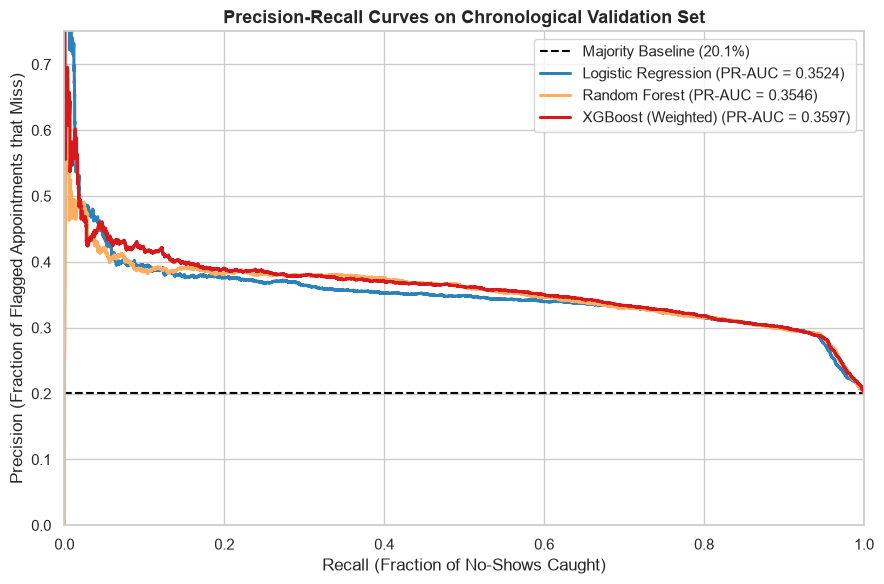

In [3]:
models_dict = {
    'Logistic Regression': pipe_lr,
    'Random Forest': pipe_rf,
    'XGBoost (Weighted)': pipe_xgb
}

plt.figure(figsize=(9, 6))
baseline_prevalence = y_val.mean()
plt.axhline(baseline_prevalence, color='black', linestyle='--', label=f'Majority Baseline ({baseline_prevalence*100:.1f}%)')

colors = {'Logistic Regression': '#2b83ba', 'Random Forest': '#fdae61', 'XGBoost (Weighted)': '#d7191c'}

for name, model in models_dict.items():
    y_prob = model.predict_proba(X_val)[:, 1]
    prec, rec, _ = precision_recall_curve(y_val, y_prob)
    pr_auc = average_precision_score(y_val, y_prob)
    plt.plot(rec, prec, label=f'{name} (PR-AUC = {pr_auc:.4f})', color=colors[name], lw=2.2)

plt.title('Precision-Recall Curves on Chronological Validation Set', fontsize=13, fontweight='bold')
plt.xlabel('Recall (Fraction of No-Shows Caught)')
plt.ylabel('Precision (Fraction of Flagged Appointments that Miss)')
plt.legend(loc='upper right', frameon=True)
plt.xlim(0, 1)
plt.ylim(0, 0.75)
plt.tight_layout()
plt.show()


## 4. Receiver Operating Characteristic (ROC) Curves

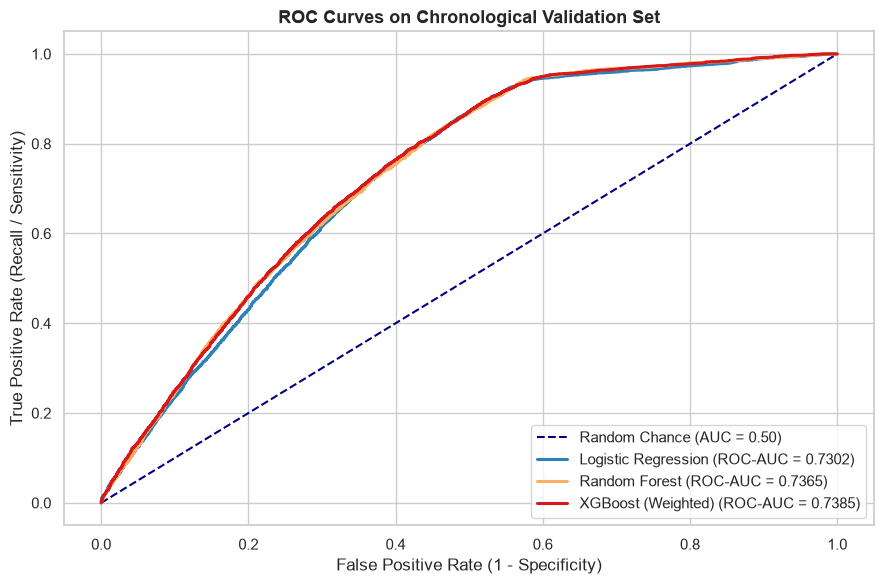

In [4]:
plt.figure(figsize=(9, 6))
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Chance (AUC = 0.50)')

for name, model in models_dict.items():
    y_prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    auc_val = roc_auc_score(y_val, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (ROC-AUC = {auc_val:.4f})', color=colors[name], lw=2.2)

plt.title('ROC Curves on Chronological Validation Set', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 5. Probability Calibration & Reliability Curves (Brier Score Analysis)
Brier Score is a proper scoring rule decomposing into Calibration (Reliability) and Discrimination (Resolution).
An unweighted model yields well-calibrated probabilities close to empirical rates, whereas `scale_pos_weight` shifts the distribution upward to elevate default recall.


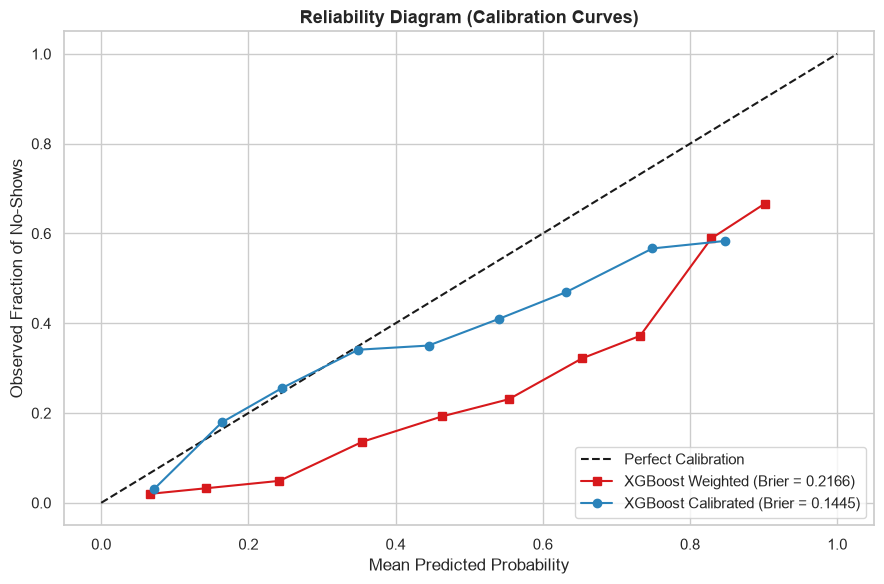

In [5]:
plt.figure(figsize=(9, 6))
plt.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')

y_prob_xgb = pipe_xgb.predict_proba(X_val)[:, 1]
y_prob_cal = pipe_xgb_cal.predict_proba(X_val)[:, 1]

prob_true_xgb, prob_pred_xgb = calibration_curve(y_val, y_prob_xgb, n_bins=10)
prob_true_cal, prob_pred_cal = calibration_curve(y_val, y_prob_cal, n_bins=10)

brier_xgb = brier_score_loss(y_val, y_prob_xgb)
brier_cal = brier_score_loss(y_val, y_prob_cal)

plt.plot(prob_pred_xgb, prob_true_xgb, 's-', color='#d7191c', label=f'XGBoost Weighted (Brier = {brier_xgb:.4f})')
plt.plot(prob_pred_cal, prob_true_cal, 'o-', color='#2b83ba', label=f'XGBoost Calibrated (Brier = {brier_cal:.4f})')

plt.title('Reliability Diagram (Calibration Curves)', fontsize=13, fontweight='bold')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Fraction of No-Shows')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 6. Ablation Studies (Validated on Holdout Set)
1. **Incremental Value of `same_day_booking`:** Does adding a binary flag derived from `lead_days == 0` add predictive power to tree models?
2. **Feature Group Incremental Lift:** Measuring performance progression from Static -> Static+Temporal -> Full (with Patient History).


In [6]:
ab_sameday = bench_data['ablation_same_day_booking']
ab_groups = bench_data['ablation_feature_groups']

print("--- Ablation 1: same_day_booking ---")
print(f"XGBoost WITH same_day_booking:    PR-AUC = {ab_sameday['pr_auc_with']:.4f}")
print(f"XGBoost WITHOUT same_day_booking: PR-AUC = {ab_sameday['pr_auc_without']:.4f}")
print(f"Delta: {ab_sameday['delta_pr_auc']:+.4f} -> {ab_sameday['conclusion']}")

print("\n--- Ablation 2: Feature Group Incremental Lift ---")
ab_df = pd.DataFrame([
    {'Group': 'A: Static Features Only (7 feat)', 'PR_AUC': ab_groups['group_a_static']['pr_auc'], 'ROC_AUC': ab_groups['group_a_static']['roc_auc'], 'Incremental_Lift': '-'},
    {'Group': 'B: Static + Temporal (12 feat)', 'PR_AUC': ab_groups['group_b_static_temporal']['pr_auc'], 'ROC_AUC': ab_groups['group_b_static_temporal']['roc_auc'], 'Incremental_Lift': f"+{ab_groups['group_b_static_temporal']['lift_over_static']:.4f}"},
    {'Group': 'C: Full Model (+ History, 17 feat)', 'PR_AUC': ab_groups['group_c_full']['pr_auc'], 'ROC_AUC': ab_groups['group_c_full']['roc_auc'], 'Incremental_Lift': f"+{ab_groups['group_c_full']['lift_over_temporal']:.4f}"}
])
ab_df


--- Ablation 1: same_day_booking ---
XGBoost WITH same_day_booking:    PR-AUC = 0.3597
XGBoost WITHOUT same_day_booking: PR-AUC = 0.3573
Delta: +0.0024 -> Derived same_day_booking provides minimal incremental lift as tree models naturally partition at lead_days == 0.

--- Ablation 2: Feature Group Incremental Lift ---


,Group,PR_AUC,ROC_AUC,Incremental_Lift
0,A: Static Features Only (7 feat),0.2426,0.5692,-
1,B: Static + Temporal (12 feat),0.3535,0.7347,+0.1109
2,"C: Full Model (+ History, 17 feat)",0.3597,0.7385,+0.0062


## 7. Interpretability: Logistic Regression Odds Ratios
Because continuous features are standardized and days of week are one-hot encoded, exponentiating the learned coefficients ($e^{\beta}$) provides directional **Odds Ratios**.


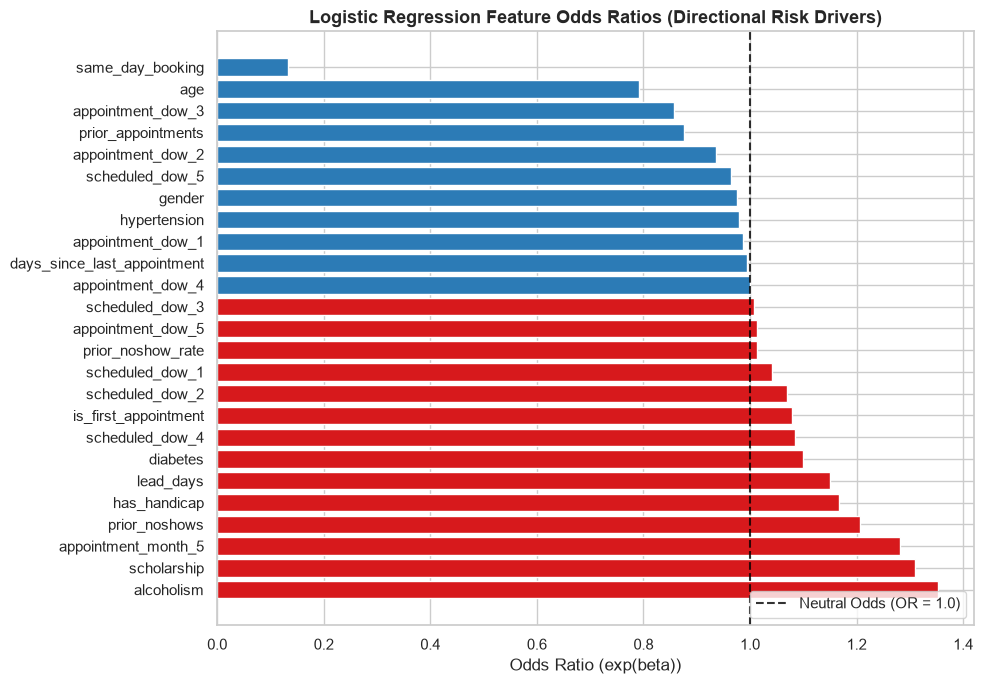

Top 5 Risk Factors (OR > 1.0):
            Feature  Coefficient  Odds_Ratio
         alcoholism     0.302071    1.352657
        scholarship     0.270184    1.310205
appointment_month_5     0.247883    1.281310
      prior_noshows     0.188264    1.207153
       has_handicap     0.154117    1.166627

Top 5 Protective / Adherence Factors (OR < 1.0):
           Feature  Coefficient  Odds_Ratio
 appointment_dow_2    -0.066652    0.935521
prior_appointments    -0.132321    0.876060
 appointment_dow_3    -0.153814    0.857431
               age    -0.233803    0.791517
  same_day_booking    -2.011824    0.133744


In [7]:
cat_names = list(pipe_lr.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(['appointment_dow', 'scheduled_dow', 'appointment_month']))
num_names = ['age', 'lead_days', 'prior_appointments', 'prior_noshows', 'prior_noshow_rate', 'days_since_last_appointment']
bin_names = ['gender', 'scholarship', 'hypertension', 'diabetes', 'alcoholism', 'has_handicap', 'same_day_booking', 'is_first_appointment']
all_feature_names = cat_names + num_names + bin_names

coefs = pipe_lr.named_steps['clf'].coef_[0]
odds_ratios = np.exp(coefs)

df_or = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': coefs,
    'Odds_Ratio': odds_ratios
}).sort_values(by='Odds_Ratio', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 7))
colors_or = ['#d7191c' if v > 1.0 else '#2c7bb6' for v in df_or['Odds_Ratio']]
plt.barh(df_or['Feature'], df_or['Odds_Ratio'], color=colors_or)
plt.axvline(1.0, color='black', linestyle='--', alpha=0.8, label='Neutral Odds (OR = 1.0)')
plt.title('Logistic Regression Feature Odds Ratios (Directional Risk Drivers)', fontsize=13, fontweight='bold')
plt.xlabel('Odds Ratio (exp(beta))')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("Top 5 Risk Factors (OR > 1.0):")
print(df_or.head(5).to_string(index=False))
print("\nTop 5 Protective / Adherence Factors (OR < 1.0):")
print(df_or.tail(5).to_string(index=False))


## 8. XGBoost Feature Importance (Gain)

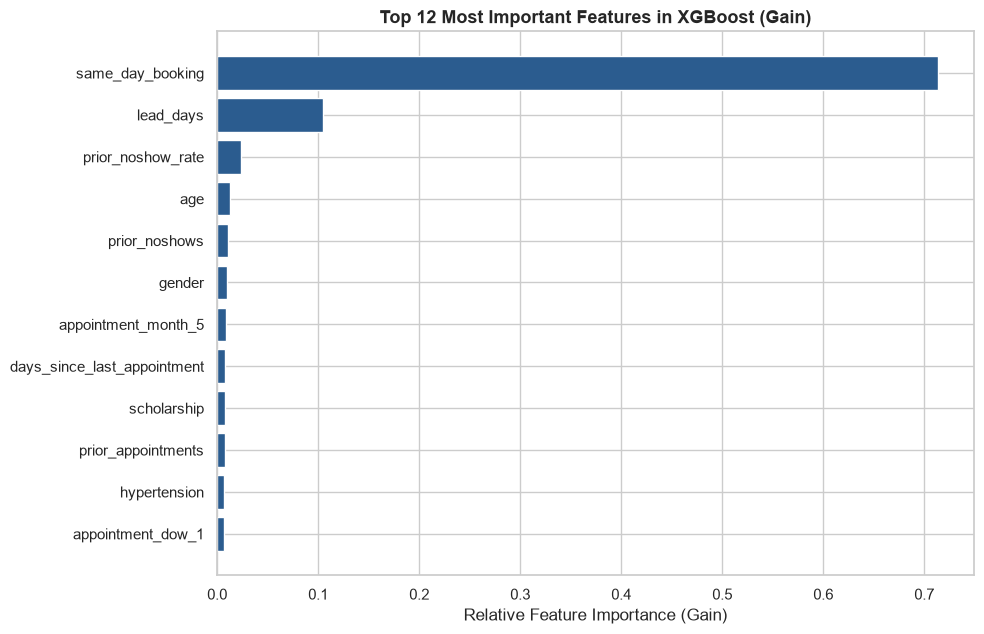

Top 10 Feature Importances in XGBoost:
                    Feature  Importance_Gain
           same_day_booking         0.713507
                  lead_days         0.104879
          prior_noshow_rate         0.023202
                        age         0.012897
              prior_noshows         0.010785
                     gender         0.009631
        appointment_month_5         0.009040
days_since_last_appointment         0.007782
                scholarship         0.007642
         prior_appointments         0.007421


In [8]:
xgb_model = pipe_xgb.named_steps['clf']
xgb_importances = xgb_model.feature_importances_

df_imp = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance_Gain': xgb_importances
}).sort_values(by='Importance_Gain', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6.5))
plt.barh(df_imp['Feature'].head(12)[::-1], df_imp['Importance_Gain'].head(12)[::-1], color='#2b5c8f')
plt.title('Top 12 Most Important Features in XGBoost (Gain)', fontsize=13, fontweight='bold')
plt.xlabel('Relative Feature Importance (Gain)')
plt.tight_layout()
plt.show()

print("Top 10 Feature Importances in XGBoost:")
print(df_imp.head(10).to_string(index=False))


## 9. Handoff to Step 5: Cost-Sensitive Threshold Optimization & Economic Theory

### **Key Conclusions from Benchmarking:**
1. **XGBoost achieves the highest discriminative performance** on unseen validation appointments (PR-AUC = 0.3597, ROC-AUC = 0.7385), outperforming Logistic Regression (0.3524) and Random Forest (0.3546).
2. **Calibration Protocol Verification:** CalibratedClassifierCV fitted strictly via 5-fold cross-validation on the Training partition produces well-calibrated probabilities on Validation (Brier = 0.1445, ECE = 0.0359), matching the unweighted base model (Brier = 0.1431, ECE = 0.0240). Class weighting (`scale_pos_weight`) deliberately distorts probability calibration to shift sensitivity at default 0.50.
3. **`same_day_booking` is redundant for tree models** (delta PR-AUC = +0.0024).
4. **Temporal and Patient History features** provide almost all predictive lift over demographic baselines.

### 🎯 Economic Threshold Derivation (Illustrative Parameters):
Under simplified operational assumptions:
* **Cost of False Negative (Missed Visit / Idle Physician Slot):** \$200 (illustrative operational cost).
* **Cost of False Positive (Unnecessary Reminder Outreach):** \$10 (illustrative outreach cost).

#### **Mathematical Derivation:**
For an appointment with predicted no-show probability $p$:
* Expected Loss of Intervening ($\hat{Y} = 1$): $E[\text{Loss} | \hat{Y}=1] = p \cdot C_{TP} + (1-p) \cdot C_{FP}$
* Expected Loss of No Action ($\hat{Y} = 0$): $E[\text{Loss} | \hat{Y}=0] = p \cdot C_{FN} + (1-p) \cdot C_{TN}$

Setting $C_{TN} = \$0$ and $C_{FP} = \$10$:
* **Under 100% Intervention Efficacy ($r = 1.0$):** $C_{TP} = \$10$
  $$10 < p \cdot 200 \implies p^* = \frac{10}{200} = \mathbf{0.0500} \text{ (5.0\%)}$$
* **Under Realistic Partial Efficacy ($r < 1.0$):** Outreach only prevents fraction $r$ of misses:
  $$C_{TP} = 10 + (1-r) \cdot 200$$
  $$10 + (1-r) \cdot 200 \cdot p < 200 \cdot p \implies p^* = \frac{10}{200 \cdot r}$$
  * If efficacy $r = 33\% \implies p^* \approx \mathbf{0.15}$
  * If efficacy $r = 25\% \implies p^* = \mathbf{0.20}$
  * If efficacy $r = 20\% \implies p^* = \mathbf{0.25}$

> **Important Disclosure:** These costs and efficacies are illustrative economic parameters for demonstrating cost-sensitive threshold selection, not measured financial outcomes. Outreach may not prevent every no-show, and real-world implementation requires empirical clinical efficacy trials.
